In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import  matplotlib.pyplot as plt
import re
import math

In [187]:
df_final= pd.read_excel('C:/Users/pc/Documents/my_thesis/research_data/new data/final_imp.xlsx')

# LOS_days Outlier Removal Using IQR

In [188]:

# Calculate IQR upper bound
Q1 = df_final['LOS_days'].quantile(0.25)
Q3 = df_final['LOS_days'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5* IQR

# Keep only valid LOS_days
df_final = df_final[(df_final['LOS_days'] >= 1) & (df_final['LOS_days'] <= upper_bound)]

In [189]:

clinical_limits = {
    'hr': (30, 250),
    'sbp': (40, 300),
    'dbp': (20, 180),
    'rr': (5, 80),
    'temp': (30, 45),
    'spo2': (0, 101),
    'rbs': (20, 1000),
    'Pain_score': (0, 10),
    'sodium': (100, 180),
    'potassium': (1.5, 10),

    'wbc': (0.1, 300),
    'rbc': (0.5, 10),

    'basophil': (0, 20),
    'eosinophil': (0, 40),
    'monocyte': (0, 30),
    'neutrophil': (0, 100),
    'lymphocyte': (0, 100),
    'hemoglobin': (2, 25),
    'hematocrit': (5, 80),
    'mcv': (50, 150),
    'mch': (10, 50),
    'mchc': (20, 45),
    'mpv': (5, 20),
    'plt': (5, 2000),
    'ast_sgot': (0, 5000),
    'alt_sgpt': (0, 5000),
    'creatinine': (0.1, 20),
    'oxy_use': (0, 100),
    'Age_years': (13, 120)
}
# Backup Original Dataset
df_original = df_final.copy()
# Replace Clinical Outliers with NaN
# ==========================================
print("Replacing values outside clinical limits...\n")

for col, (low, high) in clinical_limits.items():

    outliers = (df_final[col] < low) | (df_final[col] > high)
    n_outliers = outliers.sum()

    df_final.loc[outliers, col] = np.nan

Replacing values outside clinical limits...



In [190]:
from itables import init_notebook_mode, show

init_notebook_mode(all_interactive=True)
numeric_cols = [
    'hr', 'sbp', 'dbp', 'rr', 'temp', 'spo2', 'rbs', 'Pain_score',
    'sodium', 'potassium', 'wbc', 'rbc', 'basophil', 'eosinophil',
    'monocyte', 'neutrophil', 'lymphocyte', 'hemoglobin',
    'hematocrit', 'mcv', 'mch', 'mchc', 'mpv', 'plt',
    'ast_sgot', 'alt_sgpt', 'creatinine', 'oxy_use', 'Age_years'
]
summary = pd.DataFrame({
    "Count": df_final[numeric_cols].count(),
    "Missing": df_final[numeric_cols].isna().sum(),
    "Missing (%)": (df_final[numeric_cols].isna().mean()*100).round(2),
    "Mean": df_final[numeric_cols].mean(),
    "Std": df_final[numeric_cols].std(),
    "Min": df_final[numeric_cols].min(),
    "25%": df_final[numeric_cols].quantile(0.25),
    "Median": df_final[numeric_cols].median(),
    "75%": df_final[numeric_cols].quantile(0.75),
    "Max": df_final[numeric_cols].max(),
    "Skewness": df_final[numeric_cols].skew(),
    "Kurtosis": df_final[numeric_cols].kurt()
}).round(2)

summary = summary.reset_index().rename(columns={"index": "Variable"})
# Display in Jupyter
display(summary)


Variable  Count  Missing  Missing (%)    Mean     Std     Min     25%  \
0           hr   3385       97         2.79   91.90   17.93   40.00   79.66   
1          sbp   3332      150         4.31  118.52   19.22   50.00  105.85   
2          dbp   3334      148         4.25   66.13   13.45   22.00   57.03   
3           rr   3245      237         6.81   23.37    6.49    6.00   20.00   
4         temp   3314      168         4.82   36.81    1.05   31.09   36.32   
5         spo2   3111      371        10.65   94.06    4.32   60.00   93.00   
6          rbs   3066      416        11.95  158.89   69.40   24.00  118.00   
7   Pain_score   2932      550        15.80    2.50    1.56    0.00    1.64   
8       sodium   2902      580        16.66  139.09    6.24  100.50  136.25   
9    potassium   2921      561        16.11    4.12    0.68    1.70    3.74   
10         wbc   3166      316         9.08   11.62    7.16    0.70    7.50   
11         rbc   3157      325         9.33    4.07    0.97    0.80    3.42   
12    basophil   2698      784        22.52    0.46    0.61    0.00    0.17   
13  eosinophil   2291     1191        34.20    1.22    1.91    0.00    0.20   
14    monocyte   3108      374        10.74    5.69    3.14    0.10    3.58   
15  neutrophil   3149      333         9.56   79.76   12.50    2.27   74.00   
16  lymphocyte   3147      335         9.62   12.64    9.30    0.09    5.90   
17  hemoglobin   3170      312         8.96   11.97    2.89    2.30    9.90   
18  hematocrit   3168      314         9.02   35.79    8.85    6.40   29.80   
19         mcv   3144      338         9.71   88.04    7.21   54.56   84.00   
20         mch   2986      496        14.24   29.49    3.18   13.95   28.00   
21        mchc   2977      505        14.50   33.40    2.05   22.07   32.40   
22         mpv   2131     1351        38.80    9.80    1.77    5.00    8.77   
23         plt   3308      174         5.00  204.05  114.21    5.00  129.00   
24    ast_sgot   1618     1864        53.53  116.61  338.90    2.50   28.00   
25    alt_sgpt   1697     1785        51.26   78.54  194.51    1.00   21.20   
26  creatinine   2927      555        15.94    1.39    1.13    0.10    0.80   
27     oxy_use   3261      221         6.35   15.02   26.67    0.00    0.00   
28   Age_years   3482        0         0.00   57.79   19.72   13.00   43.00   

    Median     75%      Max  Skewness  Kurtosis  
0    90.00  102.55   202.58      0.66      1.31  
1   116.00  129.49   225.53      0.68      1.59  
2    64.67   73.51   148.00      0.94      2.70  
3    21.97   25.00    80.00      2.53     10.87  
4    36.75   37.25    44.82      1.41     12.97  
5    95.00   96.26   101.00     -2.84     13.59  
6   141.00  178.00   573.00      2.15      6.66  
7     2.48    3.12    10.00      0.79      2.38  
8   139.00  141.74   178.00      0.23      5.98  
9     4.07    4.45     7.85      0.78      3.13  
10   10.39   14.00   197.29      7.05    147.90  
11    4.07    4.66     8.89      0.28      0.81  
12    0.45    0.45     8.80      5.81     49.28  
13    0.60    1.40    19.50      4.10     23.56  
14    5.30    7.24    29.00      1.41      4.97  
15   82.60   88.70    98.60     -1.58      4.08  
16   10.40   16.70    80.60      1.91      6.81  
17   11.90   13.80    23.20      0.23      0.36  
18   35.45   41.20    77.90      0.33      0.68  
19   88.16   92.10   130.00     -0.08      2.41  
20   29.70   31.25    48.83     -0.31      3.05  
21   33.60   34.60    42.74     -0.83      2.83  
22    9.80   10.90    18.00      0.27      1.48  
23  186.67  256.54  1121.33      1.50      5.00  
24   48.08   89.98  4510.00      9.43    104.23  
25   36.60   67.00  3027.00      8.86    100.21  
26    1.44    1.44    16.66      5.39     44.35  
27    2.00   15.00   100.00      2.06      3.19  
28   60.00   74.00    97.00     -0.27     -0.95

# 3.Categorical Variable Encoding

In [191]:
# 1. Admitted_from_Group
admit_map = {
    'Emergency': '1',
    'Medical Ward': '2',
    'Surgical Ward': '3',
    'Pediatrics Ward': '4',
    'Maternity Ward': '5',
    'Orthopedic Ward': '6',
    'HDU': '7',
    'Other Specialty Wards': '8',
    'Other': '8'
}

df_final['Admission_source'] = (
    df_final['Admission_source']
    .replace(admit_map)
    .astype('object'))
# 2. Gender
# -----------------------------
gender_map = {
    'Female': '0',
    'Male': '1'
}

df_final['Gender'] = (
    df_final['Gender']
    .replace(gender_map)
    .astype('object')
)

# -----------------------------
# 3. Diagnosis Superclass
# -----------------------------
diag_map = {
    'Cardiovascular Disease': '1',
    'Respiratory Disease': '2',
    'Neurological Disease': '3',
    'Sepsis / Infection': '4',
    'Gastrointestinal / Hepatic Disease': '5',
    'Trauma / Toxicology': '6',
    'Endocrine / Metabolic Disease': '7',
    'Renal Disease': '8',
    'Thromboembolism': '9',
    'Malignancy': '10',
    'Multi-organ Failure': '11',
    'Obstetric / Gynecology': '12',
    'Autoimmune / Systemic Disease': '13',
    'Other': '14'}
df_final['case_category'] = (
    df_final['case_category']
    .replace(diag_map)
    .astype('object'))

#  feature enginering

In [192]:

# Avoid division by zero
eps = 1e-6
# 3. Shock Index (SI)
df_final['Shock_Index'] = df_final['hr'] / (df_final['sbp'] + eps)
# Create WBC-Temperature interaction feature
df_final['WBC_Temp'] = df_final['wbc'] * df_final['temp']

# removing readmission

In [104]:
# ============================================================
# REMOVE DUPLICATE MRNs BASED ON LOS_DAYS IQR
# ============================================================

# Calculate IQR limits
Q1 = df_final['LOS_days'].quantile(0.25)
Q3 = df_final['LOS_days'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1
upper_bound = Q3

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Accepted LOS range: {lower_bound:.2f} to {upper_bound:.2f}")


# ------------------------------------------------------------
# Identify rows that satisfy the preferred condition
# ------------------------------------------------------------

valid_los = (
    df_final['LOS_days'].ge(1) &
    df_final['LOS_days'].ge(lower_bound) &
    df_final['LOS_days'].le(upper_bound)
)

def select_patient_record(group):
    # If MRN is duplicated
    if len(group) > 1:

        # Rows satisfying LOS criteria
        valid_rows = group[valid_los.loc[group.index]]

        # If at least one valid row exists,
        # keep the FIRST valid row
        if len(valid_rows) > 0:
            return valid_rows.iloc[[0]]

        # If no valid row exists,
        # keep the INITIAL row
        return group.iloc[[0]]

    # Non-duplicated MRN → keep it
    return group.iloc[[0]]

df_final = (
    df_final
    .groupby('MRN', sort=False, group_keys=False)
    .apply(select_patient_record)
    .copy())
df_final.reset_index(drop=True, inplace=True)
print("\n===== DUPLICATE MRN CLEANING =====")
print("Remaining records:", len(df_final))
print("Remaining duplicated MRNs:", df_final['MRN'].duplicated().sum())

Q1: 4.79
Q3: 16.88
IQR: 12.09
Accepted LOS range: 4.79 to 16.88

===== DUPLICATE MRN CLEANING =====
Remaining records: 2991
Remaining duplicated MRNs: 0


In [193]:
df_final['LOS_binary'] = df_final['LOS_days'].apply(
    lambda x: '<=7_days' if x <= 7 else '>7_days'
).astype('category')

In [194]:
df_final['LOS_binary'].value_counts()

LOS_binary
>7_days     2099
<=7_days    1383
Name: count, dtype: int64

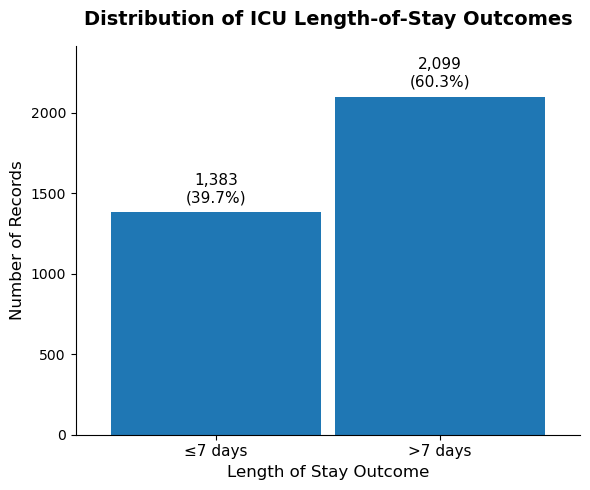

In [195]:
import matplotlib.pyplot as plt
import numpy as np

# Outcome labels
los = df_final["LOS_binary"]

# Counts and percentages
counts = los.value_counts().reindex(["<=7_days", ">7_days"])
percentages = counts / counts.sum() * 100

# Very small gap between bars
x = np.array([0, 0.32])
width = 0.30

fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(
    x,
    counts.values,
    width=width
)

# Add count and percentage labels
for bar, count, pct in zip(bars, counts.values, percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + counts.max() * 0.02,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )

# X-axis
ax.set_xticks(x)
ax.set_xticklabels(
    ["≤7 days", ">7 days"],
    fontsize=11
)

ax.set_xlabel("Length of Stay Outcome", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)

ax.set_title(
    "Distribution of ICU Length-of-Stay Outcomes",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Minimize empty space around bars
ax.set_xlim(-0.20, 0.52)
ax.set_ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.show()

In [197]:
# KEEP ONLY SELECTED VARIABLES FOR MACHINE LEARNING
selected_columns = [
    'hr',
    'sbp',
    'dbp',
    'temp',
    'spo2',
    'rbs',
    'sodium',
    'potassium',
    'neutrophil',
    'lymphocyte',
    'plt',
    'Admission_source',
    'case_category',
    'Age_years',
    'oxy_use',
    'creatinine',
    'WBC_Temp',
    'LOS_binary',   
    'rr',
    'ast_sgot',
   'hemoglobin',
   'monocyte',
    'Pain_score',
   'Shock_Index'
]
# Keep ONLY the selected columns that exist
df_final = df_final[
    [col for col in selected_columns if col in df_final.columns]
].copy()

# TRAIN-TEST SPLIT

In [199]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X = df_final.drop(columns=['LOS_binary'])
y = df_final['LOS_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("WBC_Temp in X_train:", 'WBC_Temp' in X_train.columns)
print("Shock_Index in X_train:", 'Shock_Index' in X_train.columns)
print("wbc in X_train:", 'wbc' in X_train.columns)

X_train shape: (2437, 23)
X_test shape: (1045, 23)
WBC_Temp in X_train: True
Shock_Index in X_train: True
wbc in X_train: False


In [200]:
from sklearn.model_selection import train_test_split

# 1. DEFINE PREDICTORS AND TARGET

X = df_final.drop(columns=["LOS_binary"])
y = df_final["LOS_binary"]


# ============================================================
# 2. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

Training shape: (2437, 23)
Testing shape : (1045, 23)


# IMPUTATION of missed value

In [201]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 4. NUMERICAL VARIABLES

mean_impute_cols = [
    'hr',
    'sbp',
    'dbp',
    'temp',
    'sodium',
    'potassium',
    'monocyte',
    'Age_years',
    'hemoglobin',
    'WBC_Temp',
    'Shock_Index'
     ]

median_impute_cols = [
    'rr',
    'spo2',
    'rbs',
    'neutrophil',
    'lymphocyte',
    'plt',
    'creatinine',
    'Pain_score',
    'ast_sgot',
    'oxy_use'
]
# 5. CATEGORICAL VARIABLES
categorical_cols = [
    'Admission_source',
    'case_category']

# 6. IMPUTATION TRANSFORMERS

mean_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean')) ])
median_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))])

# 7. CATEGORICAL IMPUTATION + ONE-HOT ENCODING
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            drop='first',
            sparse_output=False )) ])

# 8. COLUMN TRANSFORMER
preprocessor = ColumnTransformer(
    transformers=[
        ('mean_num', mean_transformer, mean_impute_cols),
        ('median_num', median_transformer, median_impute_cols),
        ('categorical', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# importing  LIBRARIES

In [202]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    GridSearchCV)

# RANDOM FOREST


from sklearn.ensemble import RandomForestClassifier


# ----------------------------
# XGBOOST
# ----------------------------
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from scipy.stats import randint, uniform


# ----------------------------
# PLOTS
# ----------------------------
import matplotlib.pyplot as plt


# ----------------------------
# OPTIONAL: WARNINGS
# ----------------------------
import warnings
warnings.filterwarnings('ignore')

# Define XGBoost

In [45]:
# no smote nedded

In [110]:
from xgboost import XGBClassifier

# ============================================================
# 9. XGBOOST MODEL
# ============================================================

xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# XGBOOST PIPELINE 

In [111]:
# ============================================================
# 10. XGBOOST PIPELINE — WITHOUT SMOTE
# ============================================================

from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', xgb_model)
    ]
)

# stratified cross validation

In [112]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [113]:
from scipy.stats import randint, uniform, loguniform
param_distributions_pipeline = {

    'classifier__n_estimators':
        randint(200, 800),

    'classifier__max_depth':
        randint(2, 7),

    'classifier__min_child_weight':
        randint(1, 10),

    'classifier__gamma':
        uniform(0, 0.5),

    'classifier__learning_rate':
        loguniform(0.01, 0.10),

    'classifier__subsample':
        uniform(0.70, 0.30),

    'classifier__colsample_bytree':
        uniform(0.70, 0.30),

    'classifier__reg_alpha':
        loguniform(0.001, 2),

    'classifier__reg_lambda':
        loguniform(1, 10)
}

In [114]:
# ============================================================
# CONVERT LOS TARGET TO NUMERIC CLASSES FOR XGBOOST
# <=7_days = 0
# >7_days  = 1
# ============================================================

y_train_xgb = y_train.astype(str).map({
    '<=7_days': 0,
    '>7_days': 1
}).astype(int)

# Check
print(y_train_xgb.unique())
print(y_train_xgb.value_counts(dropna=False))

[1 0]
LOS_binary
1    1313
0     780
Name: count, dtype: int64


In [115]:
print(y_train.unique())
print(y_train.value_counts(dropna=False))

['>7_days', '<=7_days']
Categories (2, object): ['<=7_days', '>7_days']
LOS_binary
>7_days     1313
<=7_days     780
Name: count, dtype: int64


In [116]:
xgb_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', xgb_model)
    ]
)

# XGBOOST — RANDOMIZED SEARCH 

In [117]:
# ============================================================
# XGBOOST RANDOMIZED SEARCH
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions_pipeline,
    n_iter=50,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score='raise'
)

# ============================================================
# FIT
# ============================================================

xgb_search.fit(
    X_train,
    y_train_xgb
)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   error_score='raise',
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('mean_num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['hr',
                                                                                'sbp',
                                                                                'dbp',
                                                                                'temp',
                                                                                'sodium',
                                                                                'potassium',
                                                                                'monocyte',
                                                                                'Age_years',
                                                                                'hemoglobin',
                                                                                'WBC_Temp',
                                                                                'Shock_Index']),
                                                                              ('median_n...
                                        'classifier__reg_alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000016D9654ACF0>,
                                        'classifier__reg_lambda': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000016D9654AF20>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x0000016D9654B070>},
                   random_state=42, scoring='roc_auc', verbose=1)

## Evaluation metrics

In [118]:
# ============================================================
# BEST XGBOOST MODEL
# ============================================================

xgb_model = xgb_search.best_estimator_

print("Best CV ROC-AUC:", xgb_search.best_score_)
print("\nBest Parameters:")
print(xgb_search.best_params_)

Best CV ROC-AUC: 0.6979128385232354

Best Parameters:
{'classifier__colsample_bytree': np.float64(0.9724797657899961), 'classifier__gamma': np.float64(0.11978094533348621), 'classifier__learning_rate': np.float64(0.013960303887216871), 'classifier__max_depth': 5, 'classifier__min_child_weight': 6, 'classifier__n_estimators': 615, 'classifier__reg_alpha': np.float64(0.09047105690021456), 'classifier__reg_lambda': np.float64(1.204629033986747), 'classifier__subsample': np.float64(0.8108963368184213)}


# FINAL TEST SET PERFORMANCE

In [119]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

# ============================================================
# FINAL XGBOOST MODEL
# ============================================================

best_xgb = xgb_search.best_estimator_

# ============================================================
# CONVERT TEST TARGET TO NUMERIC CLASSES
# <=7_days = 0
# >7_days  = 1
# ============================================================

y_test_xgb = y_test.astype(str).map({
    '<=7_days': 0,
    '>7_days': 1
}).astype(int)

# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

xgb_y_pred = best_xgb.predict(X_test)

xgb_y_prob = best_xgb.predict_proba(X_test)[:, 1]

# ============================================================
# CONFUSION MATRIX
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test_xgb,
    xgb_y_pred,
    labels=[0, 1]
).ravel()

# ============================================================
# PERFORMANCE METRICS
# ============================================================

xgb_accuracy = accuracy_score(
    y_test_xgb,
    xgb_y_pred
)

xgb_precision = precision_score(
    y_test_xgb,
    xgb_y_pred,
    pos_label=1
)

xgb_recall = recall_score(
    y_test_xgb,
    xgb_y_pred,
    pos_label=1
)

xgb_sensitivity = xgb_recall

xgb_specificity = tn / (tn + fp)

xgb_f1 = f1_score(
    y_test_xgb,
    xgb_y_pred,
    pos_label=1
)

xgb_roc_auc = roc_auc_score(
    y_test_xgb,
    xgb_y_prob
)

xgb_brier = brier_score_loss(
    y_test_xgb,
    xgb_y_prob
)

# ============================================================
# PRINT RESULTS
# ============================================================

print("XGBoost Test Performance")
print("-" * 40)
print(f"Accuracy    : {xgb_accuracy:.4f}")
print(f"Precision   : {xgb_precision:.4f}")
print(f"Recall      : {xgb_recall:.4f}")
print(f"Sensitivity : {xgb_sensitivity:.4f}")
print(f"Specificity : {xgb_specificity:.4f}")
print(f"F1-score    : {xgb_f1:.4f}")
print(f"ROC-AUC     : {xgb_roc_auc:.4f}")
print(f"Brier Score : {xgb_brier:.4f}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")
print(
    classification_report(
        y_test_xgb,
        xgb_y_pred,
        target_names=['<=7_days', '>7_days']
    )
)

XGBoost Test Performance
----------------------------------------
Accuracy    : 0.6915
Precision   : 0.7077
Recall      : 0.8670
Sensitivity : 0.8670
Specificity : 0.3952
F1-score    : 0.7793
ROC-AUC     : 0.7216
Brier Score : 0.2005

Classification Report
              precision    recall  f1-score   support

    <=7_days       0.64      0.40      0.49       334
     >7_days       0.71      0.87      0.78       564

    accuracy                           0.69       898
   macro avg       0.67      0.63      0.63       898
weighted avg       0.68      0.69      0.67       898



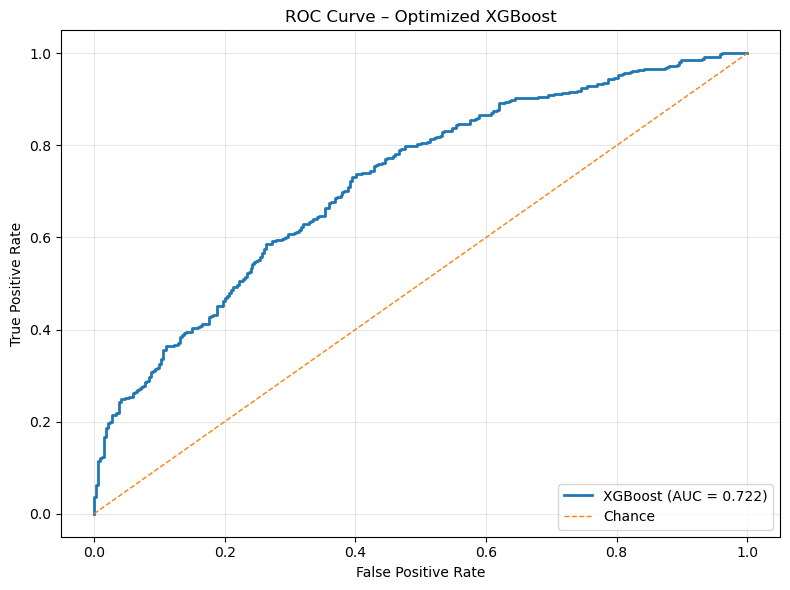

In [178]:

# ============================================================
# XGBOOST — ROC CURVE
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve
xgb_fpr, xgb_tpr, xgb_thresholds = roc_curve(
    y_test_xgb,
    xgb_y_prob
)

# Calculate ROC-AUC
xgb_roc_auc_value = auc(
    xgb_fpr,
    xgb_tpr
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {xgb_roc_auc_value:.3f})"
)

# Reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Optimized XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# XGBOOST — CALIBRATION PLOT

# Random forest model

# Define Random Forest
### Create the complete modeling pipeline

In [203]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [204]:
from sklearn.pipeline import Pipeline

# ============================================================
# RANDOM FOREST — WITHOUT SMOTE
# ============================================================

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', rf_model)
    ]
)

In [205]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestClassifier(max_depth=10, min_samples_leaf=5, min_samples_split=10,
                       n_estimators=300, n_jobs=-1, random_state=42)


## HYPERPARAMETER SEARCH SPACE

In [206]:
# ============================================================
# RANDOM FOREST — HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = {

    'classifier__n_estimators': [
        200, 300, 500
    ],

    'classifier__max_depth': [
        5, 8, 10, 12, 15
    ],

    'classifier__min_samples_split': [
        5, 10, 15, 20
    ],

    'classifier__min_samples_leaf': [
        2, 4, 6, 8
    ],

    'classifier__max_features': [
        'sqrt', 'log2'
    ],

    'classifier__bootstrap': [
        True
    ],

    'classifier__criterion': [
        'gini', 'entropy'
    ]
}

# RandomizedSearchCV

In [207]:
# RANDOM FOREST WITh SMOTE — HYPERPARAMETER SEARCH
from sklearn.model_selection import RandomizedSearchCV
rf_param_distributions = param_grid
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=50,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=2,
    return_train_score=True,
    refit=True
)

# FIT RANDOM FOREST

In [208]:
print('WBC_Temp' in X_train.columns)
print('Shock_Index' in X_train.columns)

True
True


In [209]:
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('mean_num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['hr',
                                                                                'sbp',
                                                                                'dbp',
                                                                                'temp',
                                                                                'sodium',
                                                                                'potassium',
                                                                                'monocyte',
                                                                                'Age_years',
                                                                                'hemoglobin',
                                                                                'WBC_Temp',
                                                                                'Shock_Index']),
                                                                              ('median_num',
                                                                               Pipeline(steps=[...
                   param_distributions={'classifier__bootstrap': [True],
                                        'classifier__criterion': ['gini',
                                                                  'entropy'],
                                        'classifier__max_depth': [5, 8, 10, 12,
                                                                  15],
                                        'classifier__max_features': ['sqrt',
                                                                     'log2'],
                                        'classifier__min_samples_leaf': [2, 4,
                                                                         6, 8],
                                        'classifier__min_samples_split': [5, 10,
                                                                          15,
                                                                          20],
                                        'classifier__n_estimators': [200, 300,
                                                                     500]},
                   random_state=42, return_train_score=True, scoring='roc_auc',
                   verbose=2)

#  BEST RANDOM FOREST MODEL

In [210]:
best_rf = rf_search.best_estimator_

print("Random Forest — Best Cross-Validation ROC-AUC:")
print(f"{rf_search.best_score_:.4f}")

print("\nRandom Forest — Best Parameters:")
print(rf_search.best_params_)

Random Forest — Best Cross-Validation ROC-AUC:
0.7335

Random Forest — Best Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 15, 'classifier__criterion': 'entropy', 'classifier__bootstrap': True}


In [212]:

# ============================================================
# 13. RANDOM FOREST — FINAL TEST SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ============================================================
# PREDICTIONS ON ORIGINAL, UNTOUCHED TEST SET
# ============================================================

rf_y_pred = best_rf.predict(X_test)

# Probability of >7 days LOS
rf_y_prob = best_rf.predict_proba(X_test)[:, 1]

# ============================================================
# CONFUSION MATRIX
# <=7_days = Negative class
# >7_days  = Positive class
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    rf_y_pred,
    labels=['<=7_days', '>7_days']
).ravel()

# ============================================================
# PERFORMANCE METRICS
# ============================================================

rf_accuracy = accuracy_score(
    y_test,
    rf_y_pred
)

rf_precision = precision_score(
    y_test,
    rf_y_pred,
    pos_label='>7_days',
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_y_pred,
    pos_label='>7_days',
    zero_division=0
)

rf_sensitivity = rf_recall

rf_specificity = tn / (tn + fp)

rf_f1 = f1_score(
    y_test,
    rf_y_pred,
    pos_label='>7_days',
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_y_prob
)

# ============================================================
# BRIER SCORE
# ============================================================

# Convert test outcome to 0/1 for Brier Score
y_test_rf_numeric = y_test.astype(str).map({
    '<=7_days': 0,
    '>7_days': 1
}).astype(int)

rf_brier = brier_score_loss(
    y_test_rf_numeric,
    rf_y_prob
)

# ============================================================
# RESULTS
# ============================================================

print("===== RANDOM FOREST — FINAL TEST SET PERFORMANCE =====")
print("-" * 55)

print(f"Accuracy    : {rf_accuracy:.4f}")
print(f"Precision   : {rf_precision:.4f}")
print(f"Recall      : {rf_recall:.4f}")
print(f"Specificity : {rf_specificity:.4f}")
print(f"F1 Score    : {rf_f1:.4f}")
print(f"ROC-AUC     : {rf_roc_auc:.4f}")
print(f"Brier       : {rf_brier:.4f}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        rf_y_pred,
        labels=['<=7_days', '>7_days'],
        target_names=['<=7_days', '>7_days'],
        zero_division=0
    )
)


===== RANDOM FOREST — FINAL TEST SET PERFORMANCE =====
-------------------------------------------------------
Accuracy    : 0.7014
Precision   : 0.7038
Recall      : 0.8714
Specificity : 0.4434
F1 Score    : 0.7787
ROC-AUC     : 0.7249
Brier       : 0.2044

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    <=7_days       0.69      0.44      0.54       415
     >7_days       0.70      0.87      0.78       630

    accuracy                           0.70      1045
   macro avg       0.70      0.66      0.66      1045
weighted avg       0.70      0.70      0.68      1045



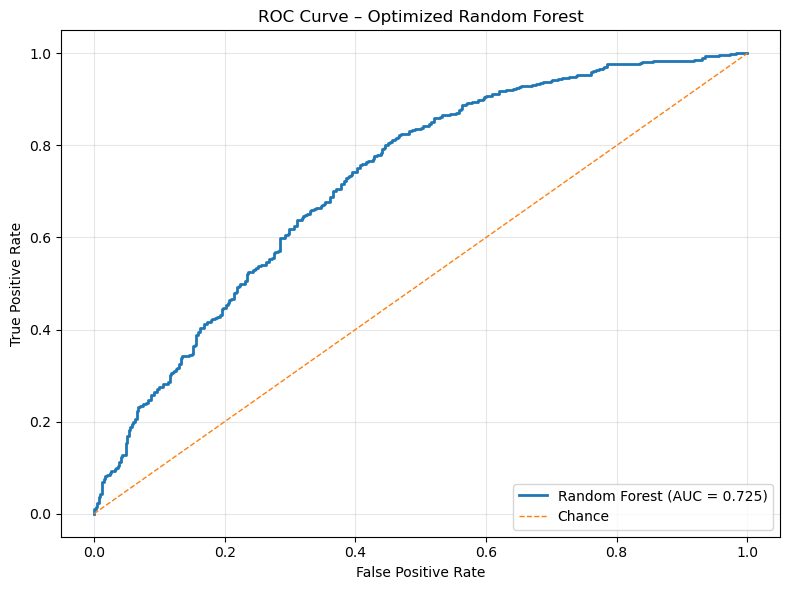

In [214]:

# ============================================================
# 14. RANDOM FOREST — ROC CURVE
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve
rf_fpr, rf_tpr, rf_thresholds = roc_curve(
    y_test,
    rf_y_prob,
    pos_label='>7_days'
)

# Calculate ROC-AUC
rf_roc_auc_value = auc(
    rf_fpr,
    rf_tpr
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {rf_roc_auc_value:.3f})"
)

# Reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Optimized Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


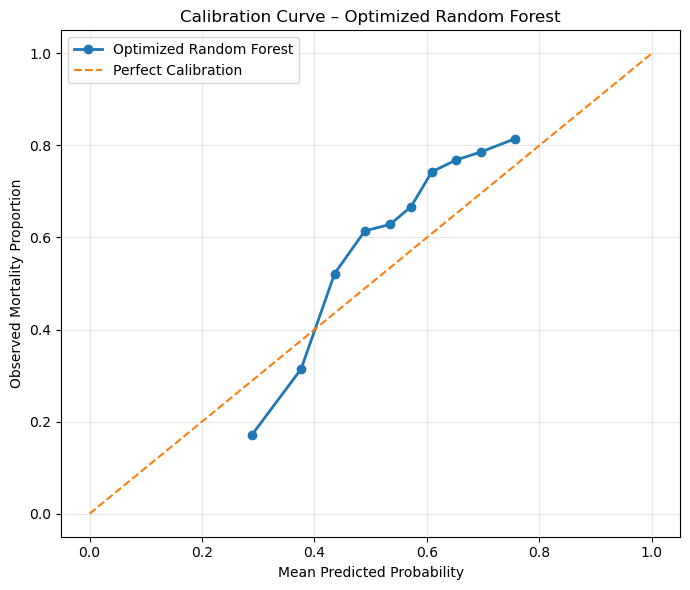

In [120]:
rf_prob_true, rf_prob_pred = calibration_curve(
    y_test,
    rf_y_prob,
    n_bins=10,
    strategy="quantile")
plt.figure(figsize=(7, 6))
plt.plot(
    rf_prob_pred,
    rf_prob_true,
    marker="o",
    linewidth=2,
    label="Optimized Random Forest")
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Mortality Proportion")
plt.title("Calibration Curve – Optimized Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [121]:
from sklearn.metrics import confusion_matrix

# Predictions
rf_y_pred = best_rf.predict(X_test)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(y_test, rf_y_pred).ravel()

# Sensitivity
rf_sensitivity = tp / (tp + fn)

# Specificity
rf_specificity = tn / (tn + fp)

print("===== RANDOM FOREST — TEST SET =====")
print(f"Sensitivity : {rf_sensitivity:.4f}")
print(f"Specificity : {rf_specificity:.4f}")

===== RANDOM FOREST — TEST SET =====
Sensitivity : 0.7643
Specificity : 0.5704


===== RANDOM FOREST — TOP 20 FEATURE IMPORTANCES =====
    Feature  Importance
        plt    0.059042
   WBC_Temp    0.055724
       temp    0.054939
 hemoglobin    0.052767
 neutrophil    0.046578
Shock_Index    0.046503
 lymphocyte    0.045358
       spo2    0.043583
   monocyte    0.043228
         hr    0.041904
 creatinine    0.040842
   ast_sgot    0.040694
        sbp    0.039630
        dbp    0.039151
  potassium    0.038307
        rbs    0.038012
  Age_years    0.037675
     sodium    0.036829
 Pain_score    0.034996
         rr    0.034349


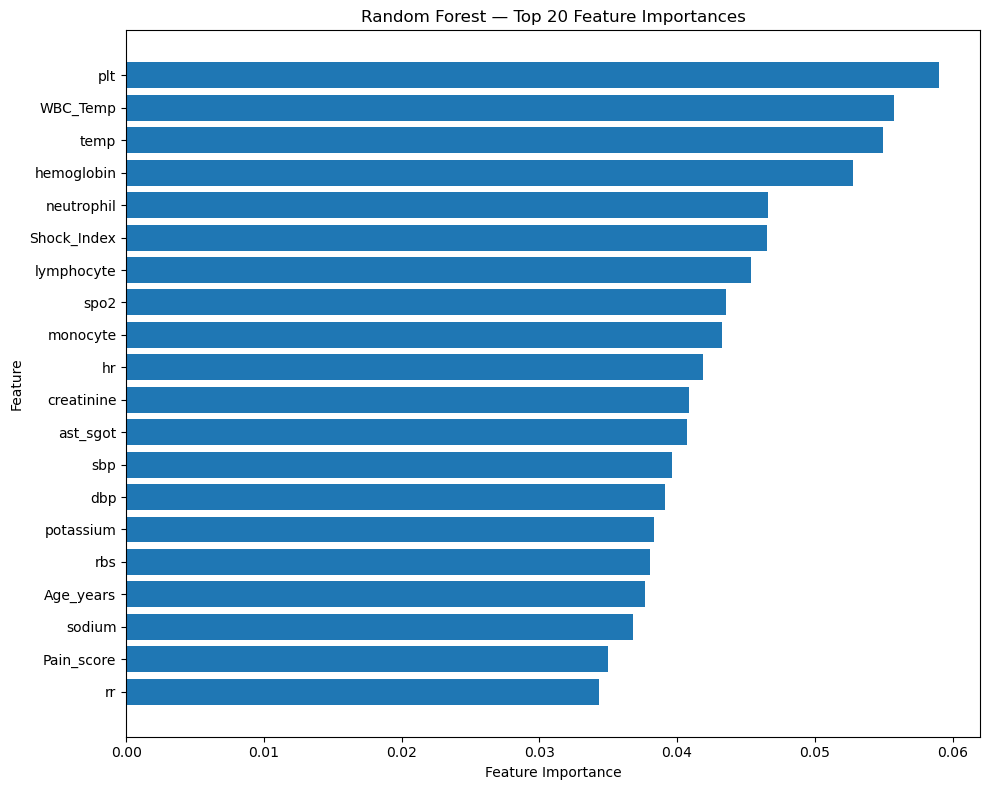

In [123]:
# ============================================================
# RANDOM FOREST — FEATURE IMPORTANCE
# CLEAN FEATURE NAMES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get fitted preprocessor
fitted_preprocessor = best_rf.named_steps['preprocessor']

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Remove preprocessing prefixes
feature_names = [
    name.split('__', 1)[1] if '__' in name else name
    for name in feature_names
]

# Get fitted Random Forest
rf_classifier = best_rf.named_steps['classifier']

# Feature importance
rf_importances = rf_classifier.feature_importances_

# Create DataFrame
rf_feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importances
})

# Sort highest to lowest
rf_feature_importance = rf_feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# ============================================================
# TOP 20 FEATURES
# ============================================================

print("===== RANDOM FOREST — TOP 20 FEATURE IMPORTANCES =====")

print(
    rf_feature_importance
    .head(20)
    .to_string(index=False)
)

# ============================================================
# PLOT TOP 20
# ============================================================

top_features = (
    rf_feature_importance
    .head(20)
    .sort_values(
        by='Importance',
        ascending=True
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest — Top 20 Feature Importances')

plt.tight_layout()
plt.show()

In [176]:
# ============================================================
# RANDOM FOREST vs XGBOOST — ROC CURVES
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------------------
# RANDOM FOREST
# ------------------------------------------------------------

rf_y_prob = best_rf.predict_proba(X_test)[:, 1]

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_y_prob
)

rf_auc = roc_auc_score(
    y_test,
    rf_y_prob
)

# ------------------------------------------------------------
# XGBOOST
# ------------------------------------------------------------

xgb_y_prob = xgb_search.predict_proba(X_test)[:, 1]

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_y_prob
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_y_prob
)

# ============================================================
# PLOT BOTH ROC CURVES
# ============================================================

plt.figure(figsize=(8, 7))

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

# Reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Chance'
)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)

plt.title(
    'ROC Curves of Random Forest and XGBoost',
    fontsize=14
)

plt.legend(
    loc='lower right',
    fontsize=10
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

ValueError: columns are missing: {'Shock_Index', 'WBC_Temp'}

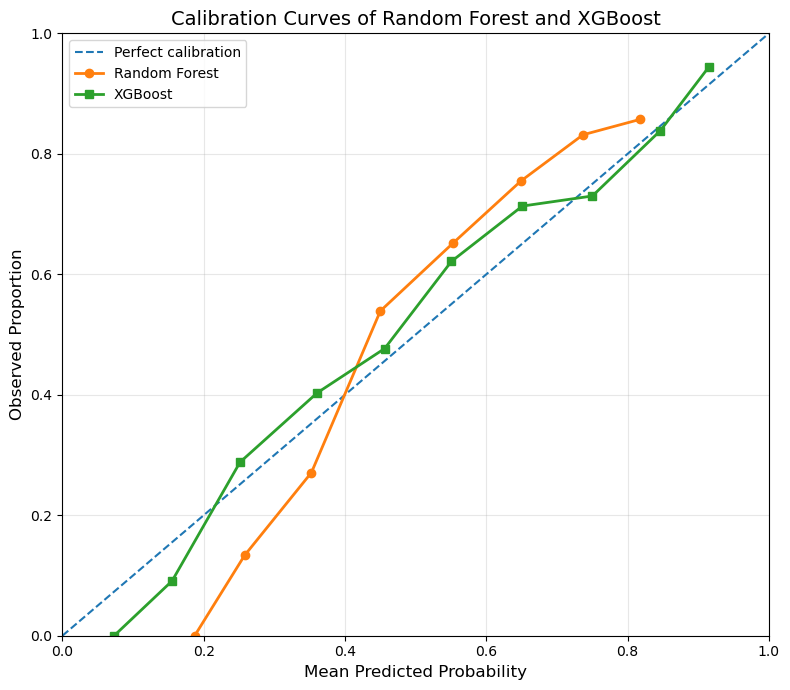

In [126]:
# ============================================================
# RANDOM FOREST vs XGBOOST — CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# PREDICTED PROBABILITIES
# ------------------------------------------------------------

# Random Forest
rf_y_prob = best_rf.predict_proba(X_test)[:, 1]

# XGBoost
xgb_y_prob = xgb_search.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# CALIBRATION CURVES
# ------------------------------------------------------------

rf_fraction_pos, rf_mean_predicted = calibration_curve(
    y_test,
    rf_y_prob,
    n_bins=10,
    strategy='uniform'
)

xgb_fraction_pos, xgb_mean_predicted = calibration_curve(
    y_test,
    xgb_y_prob,
    n_bins=10,
    strategy='uniform'
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 7))

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Perfect calibration'
)

# Random Forest
plt.plot(
    rf_mean_predicted,
    rf_fraction_pos,
    marker='o',
    linewidth=2,
    label='Random Forest'
)

# XGBoost
plt.plot(
    xgb_mean_predicted,
    xgb_fraction_pos,
    marker='s',
    linewidth=2,
    label='XGBoost'
)

# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

plt.xlabel(
    'Mean Predicted Probability',
    fontsize=12
)

plt.ylabel(
    'Observed Proportion',
    fontsize=12
)

plt.title(
    'Calibration Curves of Random Forest and XGBoost',
    fontsize=14
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(
    loc='upper left',
    fontsize=10
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# SVM MODEL and Logestic regretion

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import  matplotlib.pyplot as plt
import re
import math

In [137]:
df_final= pd.read_excel('C:/Users/pc/Documents/my_thesis/research_data/new data/final_imp.xlsx')

# LOS_days Outlier Removal Using IQR

In [138]:

# Calculate IQR upper bound
Q1 = df_final['LOS_days'].quantile(0.25)
Q3 = df_final['LOS_days'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5* IQR
# Keep only valid LOS_days
df_final = df_final[(df_final['LOS_days'] >= 1) & (df_final['LOS_days'] <= upper_bound)]

In [139]:
clinical_limits = {
    'hr': (30, 250),
    'sbp': (40, 300),
    'dbp': (20, 180),
    'rr': (5, 80),
    'temp': (30, 45),
    'spo2': (0, 101),
    'rbs': (20, 1000),
    'Pain_score': (0, 10),
    'sodium': (100, 180),
    'potassium': (1.5, 10),

    'wbc': (0.1, 300),
    'rbc': (0.5, 10),

    'basophil': (0, 20),
    'eosinophil': (0, 40),
    'monocyte': (0, 30),
    'neutrophil': (0, 100),
    'lymphocyte': (0, 100),
    'hemoglobin': (2, 25),
    'hematocrit': (5, 80),
    'mcv': (50, 150),
    'mch': (10, 50),
    'mchc': (20, 45),
    'mpv': (5, 20),
    'plt': (5, 2000),
    'ast_sgot': (0, 5000),
    'alt_sgpt': (0, 5000),
    'creatinine': (0.1, 20),
    'oxy_use': (0, 100),
    'Age_years': (13, 120)
}
# Backup Original Dataset
df_original = df_final.copy()
# Replace Clinical Outliers with NaN
# ==========================================
print("Replacing values outside clinical limits...\n")

for col, (low, high) in clinical_limits.items():

    outliers = (df_final[col] < low) | (df_final[col] > high)
    n_outliers = outliers.sum()

    df_final.loc[outliers, col] = np.nan

Replacing values outside clinical limits...



#  feature enginering

In [140]:

# Avoid division by zero
eps = 1e-6
# 3. Shock Index (SI)
df_final['Shock_Index'] = df_final['hr'] / (df_final['sbp'] + eps)
# Create WBC-Temperature interaction feature
df_final['WBC_Temp'] = df_final['wbc'] * df_final['temp']

In [141]:
df_final['LOS_binary'] = df_final['LOS_days'].apply(
    lambda x: '<=7_days' if x <= 7 else '>7_days'
).astype('category')

In [142]:
df_final['LOS_binary'].value_counts()

LOS_binary
>7_days     2099
<=7_days    1383
Name: count, dtype: int64

In [143]:
# KEEP ONLY SELECTED VARIABLES FOR MACHINE LEARNING
selected_columns = [
    'hr',
    'sbp',
    'dbp',
    'temp',
    'spo2',
    'rbs',
    'sodium',
    'potassium',
    'neutrophil',
    'lymphocyte',
    'plt',
    #'alt_sgpt',
    'Admission_source',
    'case_category',
    'Age_years',
    'oxy_use',
    'creatinine',
    #'WBC_Temp',
    'LOS_binary',   
    'rr',
    'ast_sgot',
   'hemoglobin',
   'monocyte',
    'Pain_score'
   #'Shock_Index'
]
# Keep ONLY the selected columns that exist
df_final = df_final[
    [col for col in selected_columns if col in df_final.columns]
].copy()

In [144]:
from sklearn.model_selection import train_test_split

# 1. DEFINE PREDICTORS AND TARGET

X = df_final.drop(columns=["LOS_binary"])
y = df_final["LOS_binary"]


# ============================================================
# 2. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

Training shape: (2437, 21)
Testing shape : (1045, 21)


# IMPUTATION of missed value

In [145]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ============================================================
# 4. NUMERICAL VARIABLES
# ============================================================

mean_impute_cols = [
    'hr',
    'sbp',
    'dbp',
    'temp',
    'sodium',
    'potassium',
    'monocyte',
    'Age_years',
    'hemoglobin'
    #'WBC_Temp',
    #'Shock_Index'
]

median_impute_cols = [
    'rr',
    'spo2',
    'rbs',
    'neutrophil',
    'lymphocyte',
    'plt',
    'creatinine',
    'Pain_score',
    'ast_sgot',
    'oxy_use'
]

# ============================================================
# 5. CATEGORICAL VARIABLES
# ============================================================

categorical_cols = [
    'Admission_source',
    'case_category'
]

# ============================================================
# 6. NUMERICAL IMPUTATION + STANDARDIZATION
# ============================================================

mean_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]
)

median_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# ============================================================
# 7. CATEGORICAL IMPUTATION + ONE-HOT ENCODING
# ============================================================

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            drop='first',
            sparse_output=False
        ))
    ]
)

# ============================================================
# 8. COLUMN TRANSFORMER
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ('mean_num', mean_transformer, mean_impute_cols),
        ('median_num', median_transformer, median_impute_cols),
        ('categorical', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# Logestic regression
#### LOGISTIC REGRESSION — COMPLETE MODEL PIPELINE

In [146]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

logreg_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('smote', SMOTE(
            random_state=42
        )),

        ('classifier', LogisticRegression(
            penalty='l2',
            solver='liblinear',
            random_state=42,
            max_iter=2000
        ))
    ]
)

print(logreg_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('mean_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['hr', 'sbp', 'dbp', 'temp',
                                                   'sodium', 'potassium',
                                                   'monocyte', 'Age_years',
                                                   'hemoglobin']),
                                                 ('median_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                     

In [147]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER SEARCH SPACE

logreg_param_grid = {
    'classifier__C': [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

# stratified cross validation

In [148]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

# LOGISTIC REGRESSION — GRID SEARCH

In [149]:

from sklearn.model_selection import GridSearchCV

logreg_grid_search = GridSearchCV(
    estimator=logreg_model,
    param_grid=logreg_param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
    refit=True
)

# ============================================================
# FIT LOGISTIC REGRESSION
# ============================================================

logreg_grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('mean_num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['hr',
                                                                          'sbp',
                                                                          'dbp',
                                                                          'temp',
                                                                          'sodium',
                                                                          'potassium',
                                                                          'monocyte',
                                                                          'Age_years',
                                                                          'hemoglobin']),
                                                                        ('median_num',
                                                                         Pipeline(steps=[('i...
                                                                                          OneHotEncoder(drop='first',
                                                                                                        handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Admission_source',
                                                                          'case_category'])])),
                                       ('smote', SMOTE(random_state=42)),
                                       ('classifier',
                                        LogisticRegression(max_iter=2000,
                                                           random_state=42,
                                                           solver='liblinear'))]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]},
             return_train_score=True, scoring='roc_auc', verbose=2)

###  BEST LOGISTIC REGRESSION MODEL

In [150]:
best_logreg = logreg_grid_search.best_estimator_

print("===== BEST LOGISTIC REGRESSION PARAMETERS =====")
print(logreg_grid_search.best_params_)

print(
    f"\nBest CV ROC-AUC: "
    f"{logreg_grid_search.best_score_:.4f}"
)

===== BEST LOGISTIC REGRESSION PARAMETERS =====
{'classifier__C': 0.01}

Best CV ROC-AUC: 0.6330


In [151]:
# ============================================================
# LOGISTIC REGRESSION — TEST SET PREDICTIONS
# ============================================================

logreg_y_pred = best_logreg.predict(X_test)

# Probability of LOS >7 days
logreg_y_prob = best_logreg.predict_proba(X_test)[:, 1]

In [154]:

# ============================================================
# LOGISTIC REGRESSION — TEST SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# CONFUSION MATRIX
# <=7_days = Negative class
# >7_days  = Positive class
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    logreg_y_pred,
    labels=['<=7_days', '>7_days']
).ravel()

# ============================================================
# PERFORMANCE METRICS
# ============================================================

logreg_accuracy = accuracy_score(
    y_test,
    logreg_y_pred
)

logreg_precision = precision_score(
    y_test,
    logreg_y_pred,
    pos_label='>7_days',
    zero_division=0
)

logreg_recall = recall_score(
    y_test,
    logreg_y_pred,
    pos_label='>7_days',
    zero_division=0
)

logreg_specificity = tn / (tn + fp)

logreg_f1 = f1_score(
    y_test,
    logreg_y_pred,
    pos_label='>7_days',
    zero_division=0
)

# ROC-AUC
logreg_roc_auc = roc_auc_score(
    y_test,
    logreg_y_prob
)

# ============================================================
# RESULTS
# ============================================================

print("===== LOGISTIC REGRESSION — TEST SET PERFORMANCE =====")
print("-" * 55)

print(f"Accuracy    : {logreg_accuracy:.4f}")
print(f"Precision   : {logreg_precision:.4f}")
print(f"Recall      : {logreg_recall:.4f}")
print(f"Specificity : {logreg_specificity:.4f}")
print(f"F1 Score    : {logreg_f1:.4f}")
print(f"ROC-AUC     : {logreg_roc_auc:.4f}")



===== LOGISTIC REGRESSION — TEST SET PERFORMANCE =====
-------------------------------------------------------
Accuracy    : 0.6105
Precision   : 0.6946
Recall      : 0.6317
Specificity : 0.5783
F1 Score    : 0.6617
ROC-AUC     : 0.6357


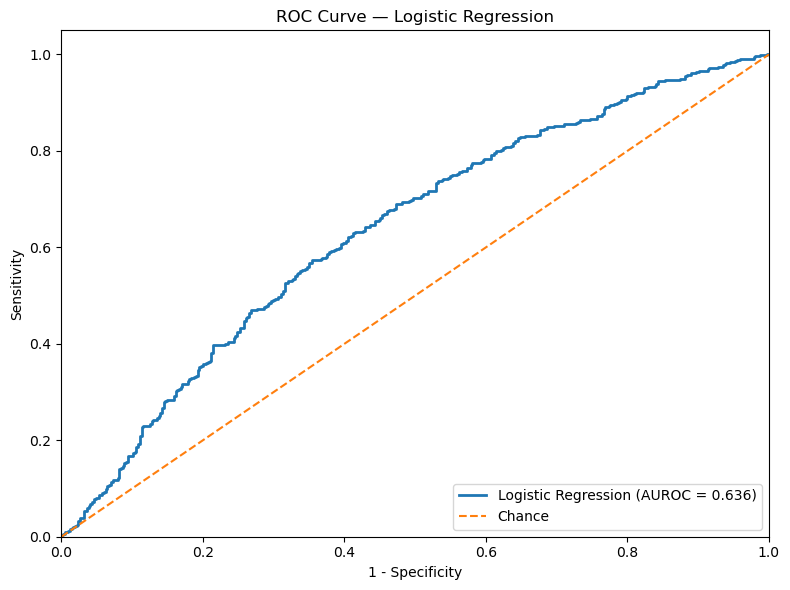

In [155]:
# ============================================================
# LOGISTIC REGRESSION — ROC CURVE
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Positive class = >7 days
y_test_binary = (y_test == '>7_days').astype(int)

# Make sure probability is for >7_days
positive_class_index = list(best_logreg.classes_).index('>7_days')

logreg_y_prob = best_logreg.predict_proba(X_test)[:, positive_class_index]

# ROC curve
logreg_fpr, logreg_tpr, _ = roc_curve(
    y_test_binary,
    logreg_y_prob
)

# AUROC
logreg_auc = roc_auc_score(
    y_test_binary,
    logreg_y_prob
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    logreg_fpr,
    logreg_tpr,
    linewidth=2,
    label=f'Logistic Regression (AUROC = {logreg_auc:.3f})'
)

# Chance line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Chance'
)

plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')

plt.title('ROC Curve — Logistic Regression')

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc='lower right')
plt.grid(False)
plt.tight_layout()

plt.show()

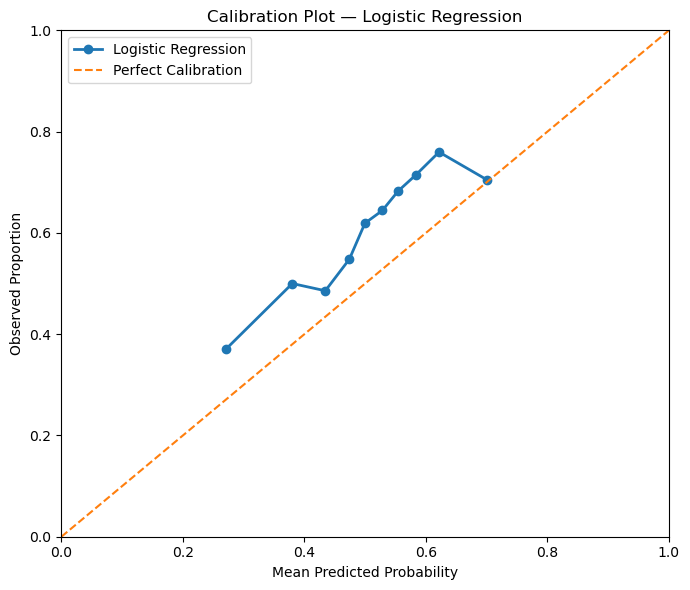

In [34]:
# ============================================================
# LOGISTIC REGRESSION — CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Positive class = >7 days
y_test_binary = (y_test == '>7_days').astype(int)

# Probability of >7 days
positive_class_index = list(best_logreg.classes_).index('>7_days')

logreg_y_prob = best_logreg.predict_proba(X_test)[:, positive_class_index]

# Calibration curve
prob_true, prob_pred = calibration_curve(
    y_test_binary,
    logreg_y_prob,
    n_bins=10,
    strategy='quantile'
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    linewidth=2,
    label='Logistic Regression'
)

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Perfect Calibration'
)

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Proportion')

plt.title('Calibration Plot — Logistic Regression')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(loc='upper left')
plt.grid(False)
plt.tight_layout()

plt.show()

# SVM

In [156]:
# ============================================================
# SVM — MODEL DEFINITION
# ============================================================

from sklearn.svm import SVC

svm = SVC(
    probability=True,
    random_state=42
)

print(svm)

SVC(probability=True, random_state=42)


In [157]:
# ============================================================
# SVM — COMPLETE MODEL PIPELINE WITH SMOTE
# ============================================================

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

svm_model_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', svm)
    ]
)

print(svm_model_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('mean_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['hr', 'sbp', 'dbp', 'temp',
                                                   'sodium', 'potassium',
                                                   'monocyte', 'Age_years',
                                                   'hemoglobin']),
                                                 ('median_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                     

In [158]:
# ============================================================
# SVM — HYPERPARAMETER SEARCH SPACE
# ============================================================

svm_param_grid = {
    'classifier__C': [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    'classifier__gamma': [
        'scale',
        0.001,
        0.01,
        0.1,
        1
    ],

    'classifier__kernel': [
        'rbf'
    ]
}

# STRATIFIED 5-FOLD CROSS-VALIDATION

In [159]:

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized Search

In [160]:
# ============================================================
# SVM — RANDOMIZED HYPERPARAMETER SEARCH
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

svm_random_search = RandomizedSearchCV(
    estimator=svm_model_pipeline,
    param_distributions=svm_param_grid,
    n_iter=30,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=2,
    return_train_score=True
)

svm_random_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('mean_num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer()),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['hr',
                                                                                'sbp',
                                                                                'dbp',
                                                                                'temp',
                                                                                'sodium',
                                                                                'potassium',
                                                                                'monocyte',
                                                                                'Age_years',
                                                                                'hemoglobin']),
                                                                              ('median_num',
                                                                               Pipeline(step...
                                                                               ['Admission_source',
                                                                                'case_category'])])),
                                             ('smote', SMOTE(random_state=42)),
                                             ('classifier',
                                              SVC(probability=True,
                                                  random_state=42))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'classifier__C': [0.01, 0.1, 1, 10,
                                                          100],
                                        'classifier__gamma': ['scale', 0.001,
                                                              0.01, 0.1, 1],
                                        'classifier__kernel': ['rbf']},
                   random_state=42, return_train_score=True, scoring='roc_auc',
                   verbose=2)

In [161]:
# ============================================================
# SVM — BEST MODEL
# ============================================================

best_svm = svm_random_search.best_estimator_

print("===== BEST SVM PARAMETERS =====")
print(svm_random_search.best_params_)

print(
    f"\nBest CV ROC-AUC: "
    f"{svm_random_search.best_score_:.4f}"
)

===== BEST SVM PARAMETERS =====
{'classifier__kernel': 'rbf', 'classifier__gamma': 'scale', 'classifier__C': 0.1}

Best CV ROC-AUC: 0.6481


In [162]:
# ============================================================
# SVM — BEST MODEL
# ============================================================

best_svm = svm_random_search.best_estimator_

print("Best SVM Parameters:")
print(svm_random_search.best_params_)

Best SVM Parameters:
{'classifier__kernel': 'rbf', 'classifier__gamma': 'scale', 'classifier__C': 0.1}


In [163]:
# ============================================================
# SVM — TEST SET PREDICTIONS
# ============================================================

svm_y_pred = best_svm.predict(X_test)

# Probability of >7 days LOS
svm_y_prob = best_svm.predict_proba(X_test)[:, 1]

print("SVM test predictions created successfully.")

SVM test predictions created successfully.


In [165]:
# ============================================================
# SVM — TEST SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

svm_accuracy = accuracy_score(
    y_test,
    svm_y_pred
)

svm_precision = precision_score(
    y_test,
    svm_y_pred,
    pos_label='>7_days'
)

svm_recall = recall_score(
    y_test,
    svm_y_pred,
    pos_label='>7_days'
)

svm_f1 = f1_score(
    y_test,
    svm_y_pred,
    pos_label='>7_days'
)

# ============================================================
# SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    svm_y_pred,
    labels=['<=7_days', '>7_days']
).ravel()

svm_specificity = tn / (tn + fp)

# ============================================================
# ROC-AUC
# ============================================================

svm_y_test_binary = (y_test == '>7_days').astype(int)

svm_roc_auc = roc_auc_score(
    svm_y_test_binary,
    svm_y_prob
)

# ============================================================
# PRINT RESULTS
# ============================================================

print("===== SVM — TEST SET PERFORMANCE =====")
print("-" * 50)
print(f"Accuracy    : {svm_accuracy:.4f}")
print(f"Precision   : {svm_precision:.4f}")
print(f"Recall      : {svm_recall:.4f}")
print(f"Specificity : {svm_specificity:.4f}")
print(f"F1 Score    : {svm_f1:.4f}")
print(f"ROC-AUC     : {svm_roc_auc:.4f}")

===== SVM — TEST SET PERFORMANCE =====
--------------------------------------------------
Accuracy    : 0.5990
Precision   : 0.6915
Recall      : 0.6048
Specificity : 0.5904
F1 Score    : 0.6452
ROC-AUC     : 0.6350


In [166]:
# ============================================================
# SVM — SENSITIVITY, SPECIFICITY & BRIER SCORE
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    brier_score_loss
)

# ------------------------------------------------------------
# Convert labels to binary
# 1 = >7_days
# 0 = <=7_days
# ------------------------------------------------------------

svm_y_test_binary = (y_test == '>7_days').astype(int)
svm_y_pred_binary = (svm_y_pred == '>7_days').astype(int)

# CONFUSION MATRIX

tn, fp, fn, tp = confusion_matrix(
    svm_y_test_binary,
    svm_y_pred_binary
).ravel()

# SENSITIVITY


svm_sensitivity = tp / (tp + fn)

# ------------------------------------------------------------
# SPECIFICITY
# ------------------------------------------------------------

svm_specificity = tn / (tn + fp)

# ------------------------------------------------------------
# BRIER SCORE
# ------------------------------------------------------------

svm_brier = brier_score_loss(
    svm_y_test_binary,
    svm_y_prob
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("===== SVM — CLINICAL & CALIBRATION METRICS =====")
print(f"Sensitivity: {svm_sensitivity:.4f}")
print(f"Specificity: {svm_specificity:.4f}")
print(f"Brier Score: {svm_brier:.4f}")

===== SVM — CLINICAL & CALIBRATION METRICS =====
Sensitivity: 0.6048
Specificity: 0.5904
Brier Score: 0.2356


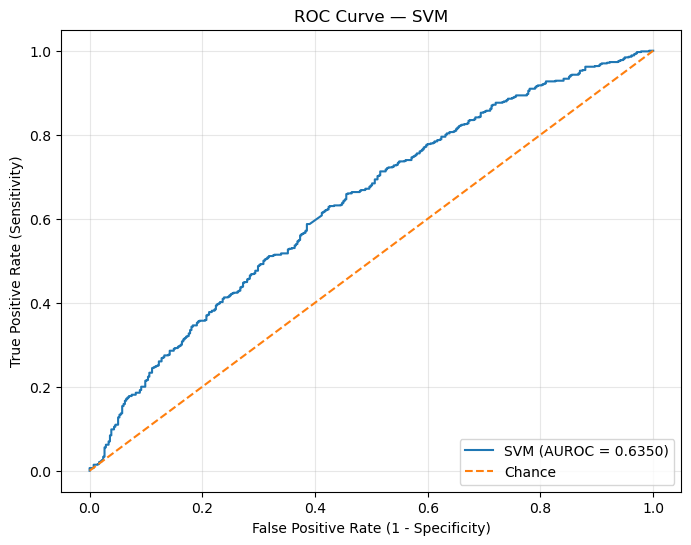

In [167]:
# ============================================================
# SVM — ROC CURVE
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Convert >7_days to positive class (1)
svm_y_test_binary = (y_test == '>7_days').astype(int)

# ROC curve
svm_fpr, svm_tpr, svm_thresholds = roc_curve(
    svm_y_test_binary,
    svm_y_prob
)

# AUROC
svm_roc_auc = roc_auc_score(
    svm_y_test_binary,
    svm_y_prob
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    svm_fpr,
    svm_tpr,
    label=f'SVM (AUROC = {svm_roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Chance'
)

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve — SVM')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

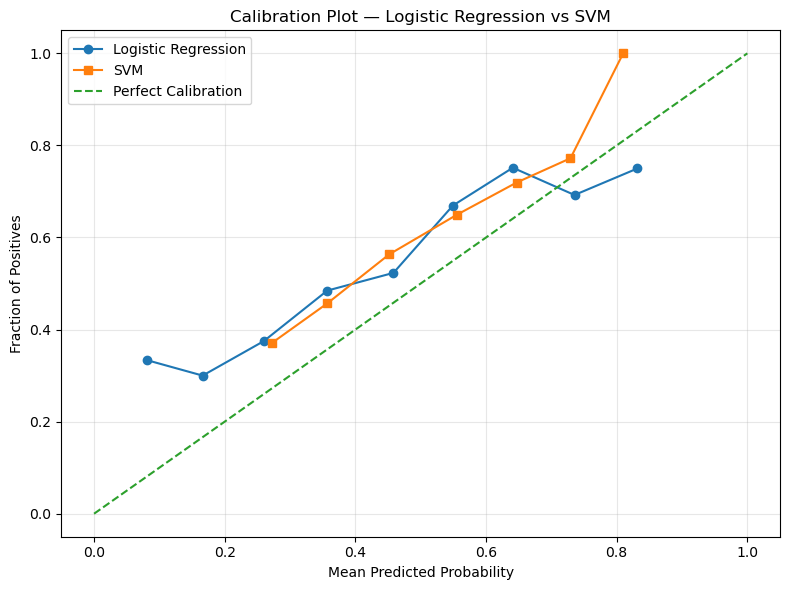

In [46]:
# ============================================================
# LOGISTIC REGRESSION + SVM — CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Convert target to binary
y_test_binary = (y_test == '>7_days').astype(int)

# Calibration curves
logreg_fraction_pos, logreg_mean_pred = calibration_curve(
    y_test_binary,
    logreg_y_prob,
    n_bins=10,
    strategy='uniform'
)

svm_fraction_pos, svm_mean_pred = calibration_curve(
    y_test_binary,
    svm_y_prob,
    n_bins=10,
    strategy='uniform')
# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    logreg_mean_pred,
    logreg_fraction_pos,
    marker='o',
    label='Logistic Regression')
plt.plot(
    svm_mean_pred,
    svm_fraction_pos,
    marker='s',
    label='SVM')
# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Perfect Calibration')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Plot — Logistic Regression vs SVM')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Model comparison

In [216]:
# ============================================================
# 4-MODEL — TEST SET PERFORMANCE COMPARISON
# ============================================================

import pandas as pd
from IPython.display import display, HTML

# Create comparison table using the exact metric variables
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'SVM',
        'XGBoost'
    ],
    
    'Accuracy': [
        logreg_accuracy,
        rf_accuracy,
        svm_accuracy,
        xgb_accuracy
    ],
    
    'Precision': [
        logreg_precision,
        rf_precision,
        svm_precision,
        xgb_precision
    ],
    
    'Recall': [
        logreg_recall,
        rf_recall,
        svm_recall,
        xgb_recall
    ],
    
    'Specificity': [
        logreg_specificity,
        rf_specificity,
        svm_specificity,
        xgb_specificity
    ],
    
    'F1 Score': [
        logreg_f1,
        rf_f1,
        svm_f1,
        xgb_f1
    ],
    
    'ROC-AUC': [
        logreg_roc_auc,
        rf_roc_auc,
        svm_roc_auc,
        xgb_roc_auc
    ]
})

# ============================================================
# INTERACTIVE HTML DISPLAY
# ============================================================

html_table = model_comparison.style \
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'Specificity': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    }) \
    .set_properties(**{
        'text-align': 'center',
        'padding': '8px',
        'border': '1px solid #999'
    }) \
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '10px'),
                ('border', '1px solid #999')
            ]
        },
        {
            'selector': 'td:first-child',
            'props': [
                ('font-weight', 'bold'),
                ('text-align', 'left')
            ]
        },
        {
            'selector': 'tbody tr:hover',
            'props': [
                ('background-color', '#f2f2f2')
            ]
        }
    ])

display(HTML(html_table.to_html()))

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
0,Logistic Regression,0.6105,0.6946,0.6317,0.5783,0.6617,0.6357
1,Random Forest,0.7014,0.7038,0.8714,0.4434,0.7787,0.7249
2,SVM,0.5990,0.6915,0.6048,0.5904,0.6452,0.6350
3,XGBoost,0.6915,0.7077,0.8670,0.3952,0.7793,0.7216


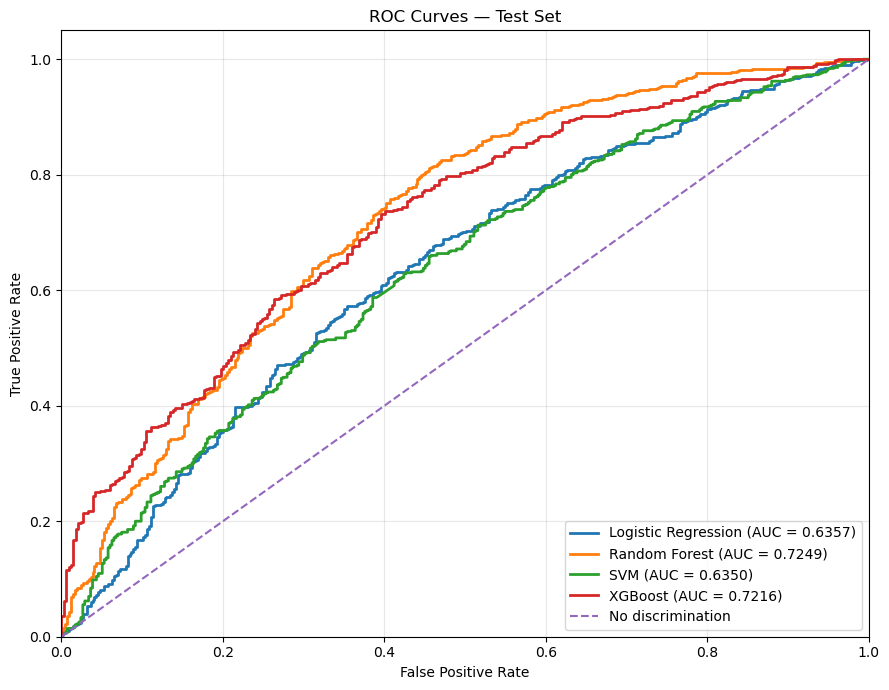

In [222]:
# ============================================================
# 4-MODEL — TEST SET ROC CURVES
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Current test labels for 3 models
y_test_binary = (y_test == '>7_days').astype(int)

# XGBoost labels from the same test set used to generate
# xgb_y_prob
xgb_test_binary = y_test_xgb.astype(int)


# Logistic Regression
logreg_fpr, logreg_tpr, _ = roc_curve(
    y_test_binary,
    logreg_y_prob
)

# Random Forest
rf_fpr, rf_tpr, _ = roc_curve(
    y_test_binary,
    rf_y_prob
)

# SVM
svm_fpr, svm_tpr, _ = roc_curve(
    y_test_binary,
    svm_y_prob
)

# XGBoost
xgb_fpr, xgb_tpr, _ = roc_curve(
    xgb_test_binary,
    xgb_y_prob
)


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(9, 7))

plt.plot(
    logreg_fpr,
    logreg_tpr,
    linewidth=2,
    label=f'Logistic Regression (AUC = {logreg_roc_auc:.4f})'
)

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f'Random Forest (AUC = {rf_roc_auc:.4f})'
)

plt.plot(
    svm_fpr,
    svm_tpr,
    linewidth=2,
    label=f'SVM (AUC = {svm_roc_auc:.4f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label='XGBoost (AUC = 0.7216)'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='No discrimination'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Test Set')

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()